# Modelo de classificação de comportamento
## Parte 1: modelo base (divisão aleatória 70/30)
Modelo inicial: Random Forest treinado e testado com janelas sorteadas aleatoriamente de todas as vacas.

In [1]:
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

# 1. Carregar e juntar os CSVs limpos de todas as vacas
files = sorted(Path("./dados/clean").glob("*.csv"))

df = pd.concat(
    (pd.read_csv(f).assign(source_file=f.name) for f in files),
    ignore_index=True,
)

# 2. Definir as colunas de atributos (estatísticas do acelerômetro)
colunas_features = [
    "x_mean",
    "x_std",
    "x_min",
    "x_max",
    "y_mean",
    "y_std",
    "y_min",
    "y_max",
    "z_mean",
    "z_std",
    "z_min",
    "z_max",
    "mag_mean",
    "mag_std",
    "mag_min",
    "mag_max",
]

X = df[colunas_features]
y = df["behavior"]

# 3. Dividir em treino (70%) e teste (30%), mantendo a proporção de classes (estratificado)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"Conjunto de Treino: {X_train.shape[0]} janelas")
print(f"Conjunto de Teste: {X_test.shape[0]} janelas")

Conjunto de Treino: 49870 janelas
Conjunto de Teste: 21374 janelas


In [2]:
from sklearn.ensemble import RandomForestClassifier

# 1. Instanciar o modelo (class_weight balanced compensa o desbalanceamento das classes)
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1,
)

# 2. Treinar o modelo com os dados de treino
print("Treinando o modelo Random Forest...")
rf_model.fit(X_train, y_train)
print("Modelo treinado com sucesso!")

Treinando o modelo Random Forest...


Modelo treinado com sucesso!


In [3]:
from sklearn.metrics import accuracy_score, classification_report

# 1. Prever os comportamentos do conjunto de teste
y_pred = rf_model.predict(X_test)

# 2. Calcular a acurácia geral
acuracia = accuracy_score(y_test, y_pred)
print(f"Acurácia Geral do Modelo: {acuracia * 100:.2f}%\n")

# 3. Exibir precisão, recall e F1 por comportamento
print("Relatório de Classificação por Comportamento:")
print(classification_report(y_test, y_pred, zero_division=0))

Acurácia Geral do Modelo: 86.05%

Relatório de Classificação por Comportamento:
              precision    recall  f1-score   support

         2.0       0.77      0.79      0.78      6078
         3.0       0.83      0.80      0.81      4383
         7.0       0.92      0.93      0.93     10913

    accuracy                           0.86     21374
   macro avg       0.84      0.84      0.84     21374
weighted avg       0.86      0.86      0.86     21374



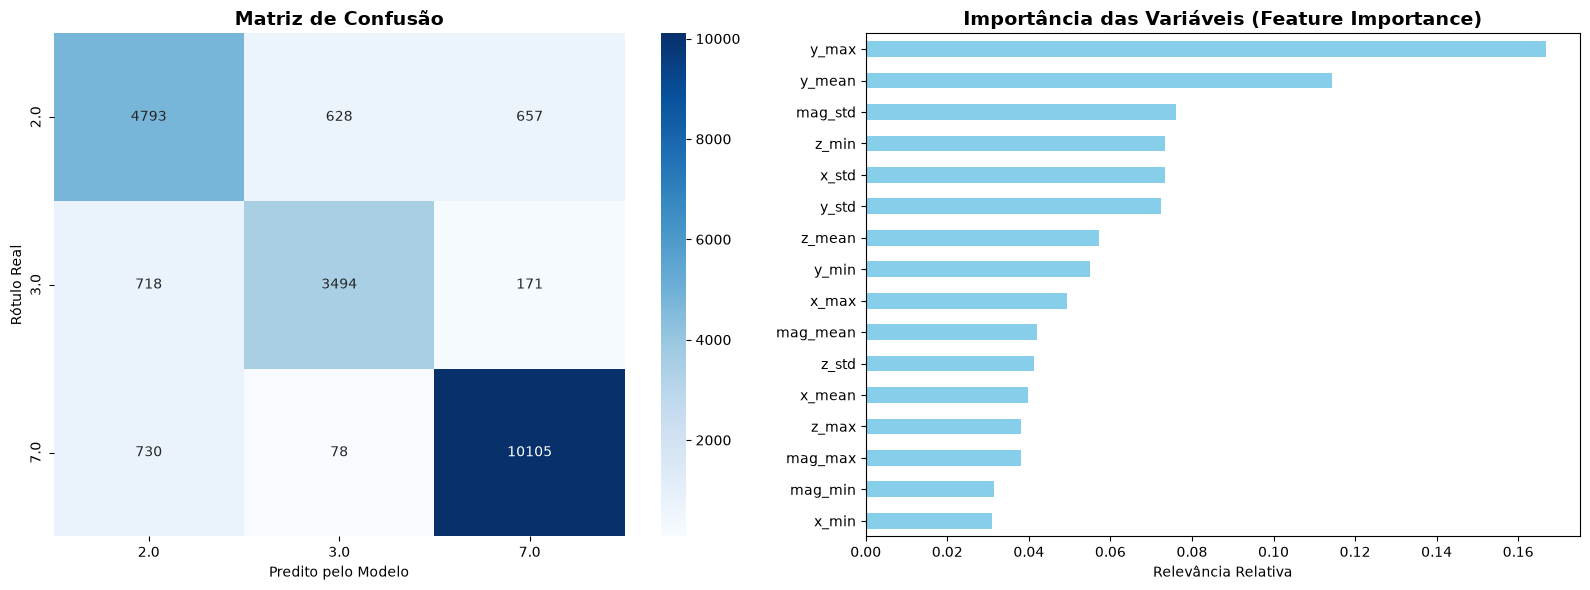

In [4]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Plotar a matriz de confusão
cm = confusion_matrix(y_test, y_pred, labels=rf_model.classes_)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=rf_model.classes_,
    yticklabels=rf_model.classes_,
    ax=axes[0],
)
axes[0].set_title("Matriz de Confusão", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Predito pelo Modelo")
axes[0].set_ylabel("Rótulo Real")

# 2. Plotar a importância dos atributos
importancias = pd.Series(
    rf_model.feature_importances_, index=colunas_features
).sort_values(ascending=True)
importancias.plot(kind="barh", color="skyblue", ax=axes[1])
axes[1].set_title(
    "Importância das Variáveis (Feature Importance)", fontsize=14, fontweight="bold"
)
axes[1].set_xlabel("Relevância Relativa")

plt.tight_layout()
plt.show()

O resultado acima (cerca de 86%) é otimista: a divisão aleatória coloca janelas vizinhas da mesma vaca no treino e no teste, e o modelo acaba "reconhecendo" a vaca.

## Parte 2: testes de melhorias
**Pergunta:** dá para melhorar o modelo?

**Hipótese:** o comportamento dura minutos, então as janelas vizinhas (antes e depois) ajudam a descobrir o que a vaca faz na janela atual.

**Como vamos avaliar:** treinando com **8 vacas** e testando nas **outras 2** (T09 e T10), que o modelo nunca viu. Assim o teste simula uma vaca nova.

**Experimentos:**
1. Chute: sempre prever "deitada".
2. Random Forest com os 16 atributos originais (ponto de partida).
3. Random Forest + atributos das 2 janelas **anteriores**.
4. Random Forest + atributos das 2 janelas anteriores e das 2 **seguintes**.
5. HistGradientBoosting (versão do scikit-learn inspirada no LightGBM) com os mesmos atributos do experimento 4.
6. GradientBoosting (o GBM clássico do scikit-learn) com os mesmos atributos do experimento 4.

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# 1. Escolher o estilo dos gráficos e criar a pasta onde as figuras serão salvas
sns.set_theme(style="whitegrid")
Path("figuras").mkdir(exist_ok=True)

# 2. Definir a ordem dos comportamentos nos gráficos (7 = deitada, 2 = em pé/andando, 3 = alimentação)
ordem = ["Deitada", "Em pé/andando", "Alimentação"]

# 3. Converter o comportamento para inteiro (o df já foi carregado na Parte 1)
df["behavior"] = df["behavior"].astype(int)

### 1. Preparar os dados e separar treino e teste
As janelas precisam estar em ordem de tempo dentro de cada vaca, para o "vizinho" ser de fato a janela de antes ou de depois.

In [6]:
# 1. Ordenar por vaca e por tempo
df = df.sort_values(["vaca_id", "janela"]).reset_index(drop=True)

# 2. Separar os 16 atributos originais, o comportamento (y) e a vaca de cada janela
colunas_base = [c for c in df.columns if c.split("_")[0] in ("x", "y", "z", "mag")]
X_base = df[colunas_base]
y = df["behavior"]
vaca_id = df["vaca_id"]

# 3. Escolher as 2 vacas de teste (as outras 8 vacas serão usadas no treino)
vacas_teste = ["T09", "T10"]
eh_teste = vaca_id.isin(vacas_teste)

print(f"{X_base.shape[1]} atributos originais")
print(f"Treino: {(~eh_teste).sum()} janelas de 8 vacas")
print(f"Teste: {eh_teste.sum()} janelas das vacas {vacas_teste}")

16 atributos originais
Treino: 56995 janelas de 8 vacas
Teste: 14249 janelas das vacas ['T09', 'T10']


### 2. Criar os atributos de contexto
Para cada janela, copiamos os atributos das janelas vizinhas da **mesma vaca**:
- `shift(1)` traz a janela de 10 s **antes**, `shift(2)` a de 20 s antes.
- `shift(-1)` traz a janela de 10 s **depois**, `shift(-2)` a de 20 s depois.

Usamos só médias e desvios padrão para não aumentar demais o número de colunas. Na primeira e na última janela de cada vaca não existe vizinho, e o valor fica vazio (NaN). O Random Forest e o HistGradientBoosting aceitam valores vazios.

Observação: se faltar alguma janela no meio (anotação removida), o vizinho pode estar a mais de 10 s de distância. Ignoramos isso para manter a lógica simples.

In [7]:
# 1. Escolher os atributos que serão copiados das janelas vizinhas
colunas_contexto = ["x_mean", "y_mean", "z_mean", "mag_mean", "x_std", "y_std", "z_std", "mag_std"]
por_vaca = df.groupby("vaca_id")[colunas_contexto]

# 2. Criar as colunas das janelas anteriores (antes1 = 10 s antes, antes2 = 20 s antes)
antes_1 = por_vaca.shift(1).add_suffix("_antes1")
antes_2 = por_vaca.shift(2).add_suffix("_antes2")

# 3. Criar as colunas das janelas seguintes
depois_1 = por_vaca.shift(-1).add_suffix("_depois1")
depois_2 = por_vaca.shift(-2).add_suffix("_depois2")

# 4. Montar as duas tabelas de atributos
X_passado = pd.concat([X_base, antes_1, antes_2], axis=1)
X_dois_lados = pd.concat([X_base, antes_1, antes_2, depois_1, depois_2], axis=1)

print(f"Atributos originais: {X_base.shape[1]}")
print(f"Com o passado: {X_passado.shape[1]}")
print(f"Com os dois lados: {X_dois_lados.shape[1]}")

Atributos originais: 16
Com o passado: 32
Com os dois lados: 48


### 3. Função para avaliar um modelo
Treinamos com as 8 vacas de treino e prevemos as 2 vacas de teste.

In [8]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

y_teste = y[eh_teste]


def avaliar(modelo, X):
    # 1. Treinar com as 8 vacas de treino
    modelo.fit(X[~eh_teste], y[~eh_teste])

    # 2. Prever o comportamento das 2 vacas de teste
    previsoes = modelo.predict(X[eh_teste])

    # 3. Calcular a acurácia e o F1 macro
    acuracia = accuracy_score(y_teste, previsoes)
    f1 = f1_score(y_teste, previsoes, average="macro")
    return acuracia, f1, previsoes


# Modelos usados nos experimentos (class_weight balanced compensa o desbalanceamento das classes)
random_forest = RandomForestClassifier(
    n_estimators=100, random_state=42, class_weight="balanced", n_jobs=-1
)
hist_gb = HistGradientBoostingClassifier(random_state=42, class_weight="balanced")

### 4. Rodar os experimentos

In [9]:
# Experimento 1: chute (sempre prever a classe mais comum, "deitada")
acuracia_chute = (y_teste == 7).mean()
f1_chute = f1_score(y_teste, [7] * len(y_teste), average="macro", zero_division=0)
print(f"Chute: acurácia {acuracia_chute:.3f} | F1 macro {f1_chute:.3f}")

Chute: acurácia 0.536 | F1 macro 0.233


In [10]:
# Experimento 2: Random Forest com os 16 atributos originais
acc_original, f1_original, prev_original = avaliar(random_forest, X_base)
print(f"RF original: acurácia {acc_original:.3f} | F1 macro {f1_original:.3f}")

RF original: acurácia 0.814 | F1 macro 0.790


In [11]:
# Experimento 3: Random Forest com o passado (janelas t-1 e t-2)
acc_passado, f1_passado, prev_passado = avaliar(random_forest, X_passado)
print(f"RF + passado: acurácia {acc_passado:.3f} | F1 macro {f1_passado:.3f}")

RF + passado: acurácia 0.853 | F1 macro 0.838


In [12]:
# Experimento 4: Random Forest com os dois lados (janelas t-2, t-1, t+1 e t+2)
acc_dois_lados, f1_dois_lados, prev_dois_lados = avaliar(random_forest, X_dois_lados)
print(f"RF + dois lados: acurácia {acc_dois_lados:.3f} | F1 macro {f1_dois_lados:.3f}")

RF + dois lados: acurácia 0.870 | F1 macro 0.857


In [13]:
# Experimento 5: HistGradientBoosting com os dois lados
acc_hgb, f1_hgb, prev_hgb = avaliar(hist_gb, X_dois_lados)
print(f"HGB + dois lados: acurácia {acc_hgb:.3f} | F1 macro {f1_hgb:.3f}")

HGB + dois lados: acurácia 0.871 | F1 macro 0.858


In [14]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

# Experimento 6: GradientBoosting (GBM clássico) com os dois lados
# Esse modelo não aceita valores vazios (NaN), então preenchemos com a mediana do treino.
# Ele também não tem class_weight, então balanceamos as classes com sample_weight.
# Atenção: é bem mais lento que os outros (cerca de 4 minutos).
mediana = X_dois_lados[~eh_teste].median()
X_dois_lados_preenchido = X_dois_lados.fillna(mediana)
pesos = compute_sample_weight("balanced", y[~eh_teste])

gbm = GradientBoostingClassifier(random_state=42)
gbm.fit(X_dois_lados_preenchido[~eh_teste], y[~eh_teste], sample_weight=pesos)

prev_gbm = gbm.predict(X_dois_lados_preenchido[eh_teste])
acc_gbm = accuracy_score(y_teste, prev_gbm)
f1_gbm = f1_score(y_teste, prev_gbm, average="macro")
print(f"GBM + dois lados: acurácia {acc_gbm:.3f} | F1 macro {f1_gbm:.3f}")

GBM + dois lados: acurácia 0.871 | F1 macro 0.857


### 5. Comparar os experimentos

In [15]:
# 1. Juntar os resultados numa tabela
tabela = pd.DataFrame(
    {
        "Acurácia": [acuracia_chute, acc_original, acc_passado, acc_dois_lados, acc_hgb, acc_gbm],
        "F1 macro": [f1_chute, f1_original, f1_passado, f1_dois_lados, f1_hgb, f1_gbm],
    },
    index=["Chute (sempre deitada)", "RF original", "RF + passado",
           "RF + dois lados", "HGB + dois lados", "GBM + dois lados"],
)

# 2. Salvar a tabela e exibir
tabela.round(3).to_csv("figuras/tabela_comparacao_modelos.csv")
tabela.round(3)

,Acurácia,F1 macro
Chute (sempre deitada),0.536,0.233
RF original,0.814,0.790
RF + passado,0.853,0.838
RF + dois lados,0.870,0.857
HGB + dois lados,0.871,0.858
GBM + dois lados,0.871,0.857


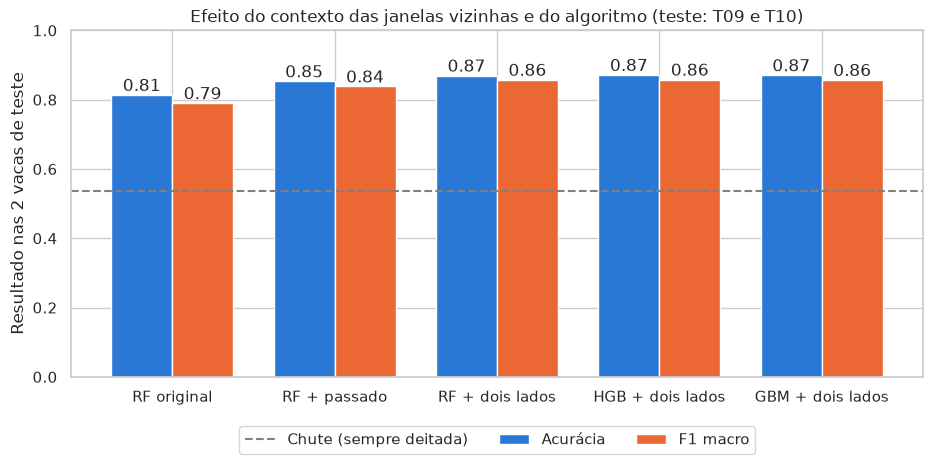

In [16]:
# 1. Separar o chute dos modelos (o chute vira uma linha tracejada)
modelos = tabela.drop(index="Chute (sempre deitada)")

# 2. Plotar barras de acurácia e F1 macro de cada experimento
ax = modelos.plot(kind="bar", color=["#2a78d6", "#eb6834"], figsize=(11, 4.5), width=0.75)
ax.axhline(acuracia_chute, color="gray", linestyle="--", label="Chute (sempre deitada)")

# 3. Escrever o valor em cima de cada barra
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.2f")

plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.title("Efeito do contexto das janelas vizinhas e do algoritmo (teste: T09 e T10)")
plt.ylabel("Resultado nas 2 vacas de teste")
plt.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.savefig("figuras/07_comparacao_experimentos.png", dpi=150, bbox_inches="tight")
plt.show()

**Como ler:**
- **Acurácia** é a porcentagem de janelas acertadas. **F1 macro** é a média do F1 das três classes, sem dar mais peso às maiores. Ele mostra se o modelo acerta também as classes menores.
- Adicionar o contexto das janelas vizinhas é o que mais melhora o modelo.
- O experimento "dois lados" usa janelas futuras. Ele serve para analisar dados já gravados, não para detectar em tempo real. A versão só com o passado é a que poderia ser usada ao vivo.
- Random Forest, HistGradientBoosting e GradientBoosting ficam praticamente empatados (87%). Escolhemos o **Random Forest** porque é mais simples de explicar e rápido. O GBM clássico leva cerca de 4 minutos para treinar, contra poucos segundos dos outros.
- XGBoost, LightGBM e CatBoost são bibliotecas externas e não foram testadas. O HistGradientBoosting do scikit-learn é a versão mais parecida com o LightGBM.

**Atenção:** o resultado depende de quais vacas ficam no teste. Em um teste separado (fora deste notebook), os cinco pares de vacas, cada um treinado nas outras 8, deram com o Random Forest + dois lados de 78,5% (T05 e T06) a 88,5% (T03 e T04), com média de 84%. Usamos T09 e T10 por serem as duas últimas vacas, sem escolher o melhor par, mas o resultado delas (87%) fica **acima** dessa média. Por isso o número de 87% não deve ser tratado como o desempenho típico em vacas novas.

### 6. Resultado em cada vaca de teste

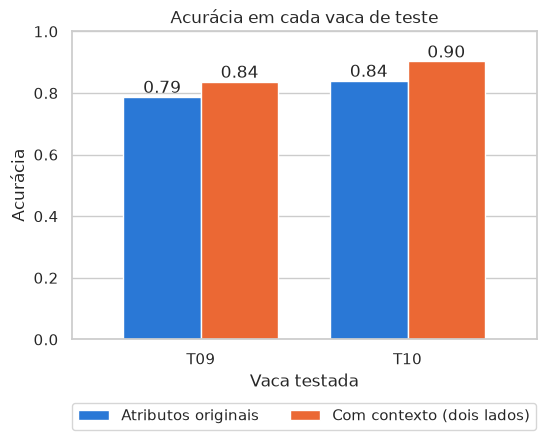

In [17]:
# 1. Calcular a acurácia de cada vaca de teste, com os atributos originais e com o contexto
vaca_teste = vaca_id[eh_teste].values
acc_por_vaca = {"Atributos originais": [], "Com contexto (dois lados)": []}
for vaca in vacas_teste:
    linhas = vaca_teste == vaca
    acc_por_vaca["Atributos originais"].append(accuracy_score(y_teste[linhas], prev_original[linhas]))
    acc_por_vaca["Com contexto (dois lados)"].append(accuracy_score(y_teste[linhas], prev_dois_lados[linhas]))
comparacao = pd.DataFrame(acc_por_vaca, index=vacas_teste)

# 2. Plotar as barras lado a lado
comparacao.plot(kind="bar", color=["#2a78d6", "#eb6834"], figsize=(6, 4), width=0.75)
for barras in plt.gca().containers:
    plt.gca().bar_label(barras, fmt="%.2f")
plt.ylim(0, 1)
plt.grid(axis="x", visible=False)
plt.xticks(rotation=0)
plt.title("Acurácia em cada vaca de teste")
plt.xlabel("Vaca testada")
plt.ylabel("Acurácia")
plt.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.18))
plt.savefig("figuras/08_acuracia_por_vaca.png", dpi=150, bbox_inches="tight")
plt.show()

### 7. Onde o modelo final ainda erra?

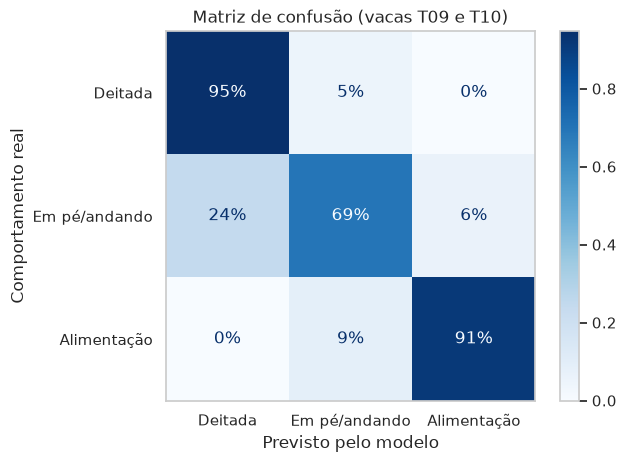

               precision    recall  f1-score   support

      Deitada      0.880     0.948     0.913      7636
Em pé/andando      0.820     0.694     0.752      4043
  Alimentação      0.902     0.913     0.907      2570

     accuracy                          0.870     14249
    macro avg      0.867     0.852     0.857     14249
 weighted avg      0.867     0.870     0.866     14249



In [18]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

# 1. Plotar a matriz de confusão (cada linha soma 100% da classe real)
ConfusionMatrixDisplay.from_predictions(
    y_teste, prev_dois_lados, labels=[7, 2, 3], display_labels=ordem,
    normalize="true", cmap="Blues", values_format=".0%",
)
plt.title("Matriz de confusão (vacas T09 e T10)")
plt.xlabel("Previsto pelo modelo")
plt.ylabel("Comportamento real")
plt.grid(False)
plt.savefig("figuras/09_matriz_confusao.png", dpi=150, bbox_inches="tight")
plt.show()

# 2. Exibir precisão, recall e F1 de cada classe
print(classification_report(y_teste, prev_dois_lados, labels=[7, 2, 3], target_names=ordem, digits=3))

Como ler a matriz: cada **linha** é o comportamento real e cada **coluna** é o que o modelo previu. A diagonal (de cima à esquerda para baixo à direita) mostra os acertos.

### 8. Quais atributos o modelo mais usa?

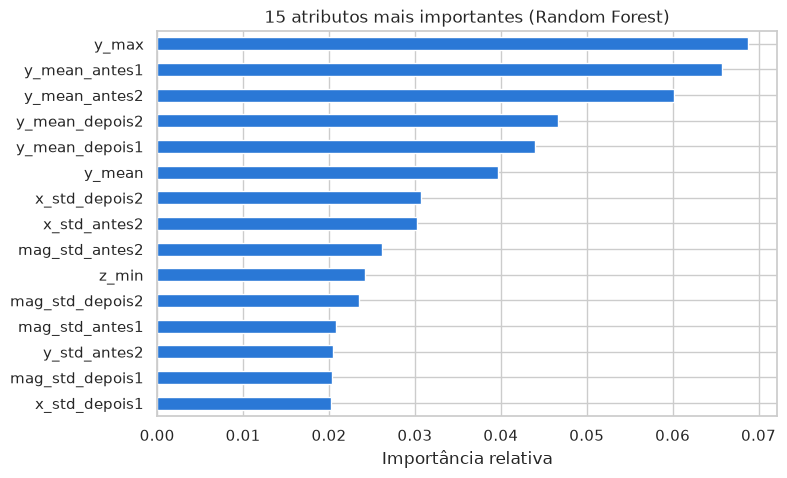

In [19]:
# 1. Treinar o Random Forest com as 8 vacas de treino (só para olhar a importância dos atributos)
modelo_final = RandomForestClassifier(
    n_estimators=100, random_state=42, class_weight="balanced", n_jobs=-1
)
modelo_final.fit(X_dois_lados[~eh_teste], y[~eh_teste])

# 2. Pegar os 15 atributos mais importantes
importancia = pd.Series(modelo_final.feature_importances_, index=X_dois_lados.columns)
top_15 = importancia.sort_values().tail(15)

# 3. Plotar as barras
top_15.plot(kind="barh", color="#2a78d6", figsize=(8, 5))
plt.title("15 atributos mais importantes (Random Forest)")
plt.xlabel("Importância relativa")
plt.savefig("figuras/10_importancia_atributos.png", dpi=150, bbox_inches="tight")
plt.show()

Os nomes mostram de onde vem cada atributo: `y_mean_antes1` é a média do eixo y na janela de 10 s anterior, e `y_mean_depois2` é a da janela 20 s depois. Sem sufixo é a janela atual.

### Conclusões
Treinando com 8 vacas e testando em T09 e T10 (vacas que o modelo nunca viu):
- O chute de sempre prever "deitada" acerta **54%** nessas duas vacas.
- O Random Forest com os 16 atributos originais chega a **81%** (F1 macro 0,79).
- Usar as janelas vizinhas como contexto sobe o resultado: **85%** só com o passado (t-1 e t-2, que funciona em tempo real) e **87%** com os dois lados (F1 macro 0,86). As duas vacas melhoram: T09 de 0,79 para 0,84 e T10 de 0,84 para 0,90.
- A classe **em pé/andando** é a mais difícil (F1 0,75): 24% das janelas dela são previstas como deitada. Deitada (95% de acerto) e alimentação (91%) são bem reconhecidas.
- Trocar o algoritmo não muda o resultado de forma relevante: HistGradientBoosting e GradientBoosting (GBM) também chegam a 87,1%. O GBM é muito mais lento.
- Este resultado vale para este par de vacas. Em outros pares o valor pode ser menor (veja o aviso na seção 5).